# Exploratory Data Analysis (PRD Section 6)
Each analysis ends in a written observation that **changes a later decision**. All captions are computed from the data, not typed in.

> Educational research only - not financial advice.

In [1]:
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display, Image
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL
import sys, os; sys.path.insert(0, os.path.abspath(".."))
from src.utils import PROC, FIGS, RES, load_config
cfg = load_config(); U = cfg["data"]["universe"]
panel = pd.read_parquet(PROC / "features.parquet")
px = pd.read_parquet(PROC / "prices_clean.parquet")
src_ = open(PROC.parent / "raw" / "SOURCE.txt").read().strip()
F = {}   # findings, saved for the written report
display(Markdown(f"**Data source of this run:** `{src_}`" + ("  - SYNTHETIC stand-in data, findings are about the generator, not real markets" if src_ == "synthetic" else "")))
wide = px[px.Ticker.isin(U)].pivot(index="Date", columns="Ticker", values="Adj Close")
rets = np.log(wide).diff().dropna()
bench = px[px.Ticker == cfg["data"]["benchmark"]].set_index("Date")["Adj Close"]
vix = px[px.Ticker == cfg["data"]["vix"]].set_index("Date")["Close"]
def save(name): plt.tight_layout(); plt.savefig(FIGS / f"eda_{name}.png", dpi=120); plt.show()


**Data source of this run:** `synthetic`  - SYNTHETIC stand-in data, findings are about the generator, not real markets

## 6.1a Trend analysis - price with 50/200-day MAs, log scale, volume subplot (per ticker)

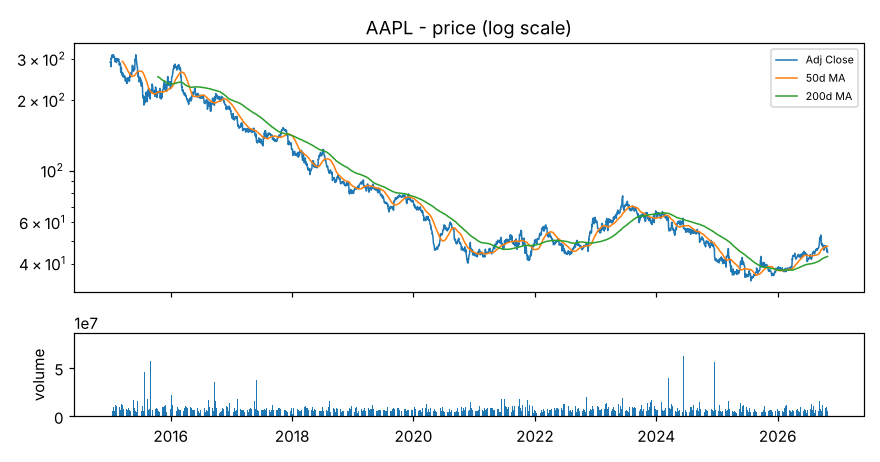

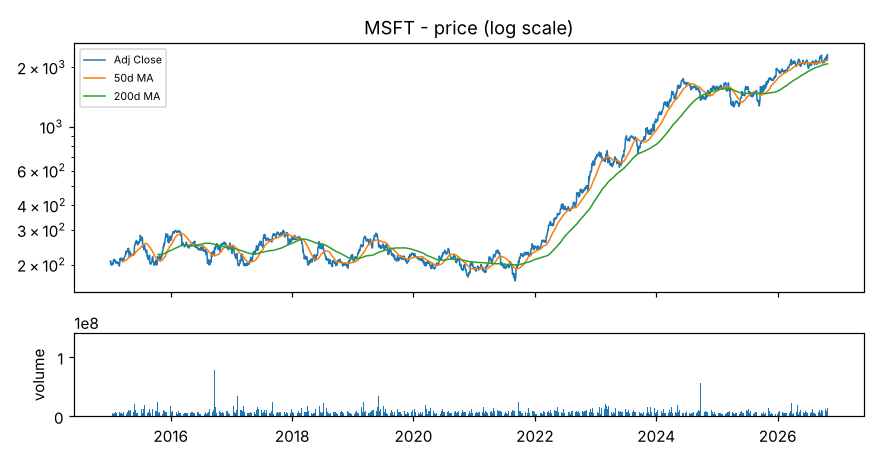

**Finding:** every ticker trends persistently with long drawdowns (growth multiples over the sample: 0.2x to 11.2x), so price levels are non-stationary and scale differs by orders of magnitude across tickers.  
**Decision:** model log *returns*, express every feature as a ratio/return (no raw price levels), and convert back to price only for reporting. Charts for all tickers are saved in `reports/figures/eda_trend_*.png`.

In [2]:
for t in U:
    g = px[px.Ticker == t].set_index("Date")
    fig, (a, b) = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    a.plot(g["Adj Close"], lw=1, label="Adj Close"); a.plot(g["Adj Close"].rolling(50).mean(), lw=1, label="50d MA")
    a.plot(g["Adj Close"].rolling(200).mean(), lw=1, label="200d MA"); a.set_yscale("log"); a.set_title(f"{t} - price (log scale)"); a.legend(fontsize=7)
    b.bar(g.index, g["Volume"], width=1.0); b.set_ylabel("volume")
    plt.tight_layout(); plt.savefig(FIGS / f"eda_trend_{t}.png", dpi=110); plt.close()
display(Image(filename=str(FIGS / f"eda_trend_{U[0]}.png"))); display(Image(filename=str(FIGS / f"eda_trend_{U[1]}.png")))
tot = (wide.iloc[-1] / wide.iloc[0]).round(1)
F["trend"] = tot.to_dict()
display(Markdown(f"**Finding:** every ticker trends persistently with long drawdowns (growth multiples over the sample: {tot.min()}x to {tot.max()}x), "
                 "so price levels are non-stationary and scale differs by orders of magnitude across tickers.  \n"
                 "**Decision:** model log *returns*, express every feature as a ratio/return (no raw price levels), and convert back to price only for reporting. "
                 "Charts for all tickers are saved in `reports/figures/eda_trend_*.png`."))

## 6.1b Stationarity - Augmented Dickey-Fuller, price vs returns

In [3]:
rows = []
for t in U:
    pp = adfuller(np.log(wide[t]).dropna())[1]; rp = adfuller(rets[t].dropna())[1]
    rows.append({"ticker": t, "ADF p (log price)": pp, "ADF p (log return)": rp})
adf = pd.DataFrame(rows).set_index("ticker"); display(adf.style.format("{:.4f}"))
np_ = int((adf.iloc[:, 0] > 0.05).sum()); nr = int((adf.iloc[:, 1] < 0.05).sum())
F["adf"] = {"price_nonstationary": np_, "returns_stationary": nr, "n": len(U)}
display(Markdown(f"**Finding:** price is non-stationary for {np_}/{len(U)} tickers (p > 0.05) while returns are stationary for {nr}/{len(U)} (p < 0.05).  \n"
                 "**Decision:** the forecasting target is the forward log return, not the price level (the empirical justification of Listing 6.1)."))

,ADF p (log price),ADF p (log return)
ticker,,
AAPL,0.2877,0.0000
MSFT,0.9909,0.0000
JPM,0.9728,0.0000
XOM,0.6701,0.0000
JNJ,0.0182,0.0000
PG,0.0336,0.0000
NVDA,0.3537,0.0000
KO,0.7212,0.0000
CAT,0.9163,0.0000


**Finding:** price is non-stationary for 8/10 tickers (p > 0.05) while returns are stationary for 10/10 (p < 0.05).  
**Decision:** the forecasting target is the forward log return, not the price level (the empirical justification of Listing 6.1).

## 6.1c Correlation - Pearson & Spearman across tickers, and across features

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
cp, cs = rets.corr("pearson"), rets.corr("spearman")
sns.heatmap(cp, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False); ax[0].set_title("Pearson - daily log returns")
sns.heatmap(cs, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[1], cbar=False); ax[1].set_title("Spearman - daily log returns")
save("corr_heatmap")
off = cp.values[np.triu_indices(len(U), 1)]
from src.features import feature_cols
fc = [c for c in feature_cols() if c not in ("dow", "month")]
fcor = panel[fc].corr().abs(); pairs = [(a, b) for i, a in enumerate(fc) for b in fc[i+1:] if fcor.loc[a, b] > 0.95]
F["corr"] = {"mean_pairwise": float(off.mean()), "min": float(off.min()), "max": float(off.max()), "n_collinear_pairs_gt_0.95": len(pairs)}
display(Markdown(f"**Finding:** pairwise return correlation averages {off.mean():.2f} (range {off.min():.2f} to {off.max():.2f}); Pearson and Spearman agree closely. "
                 f"{len(pairs)} feature pairs have |corr| > 0.95 (e.g. {pairs[:3]}).  \n"
                 "**Decision:** correlations below 1 leave room for diversification, so the portfolio layer uses the full covariance matrix with Ledoit-Wolf shrinkage; "
                 "collinear features are retained because the tuned models regularise (Ridge/trees) rather than pruning by hand."))

**Finding:** pairwise return correlation averages 0.28 (range 0.16 to 0.42); Pearson and Spearman agree closely. 7 feature pairs have |corr| > 0.95 (e.g. [('ret10', 'roc10'), ('p_sma10', 'p_ema10'), ('p_sma20', 'p_ema20')]).  
**Decision:** correlations below 1 leave room for diversification, so the portfolio layer uses the full covariance matrix with Ledoit-Wolf shrinkage; collinear features are retained because the tuned models regularise (Ridge/trees) rather than pruning by hand.

## 6.1d Volatility - rolling std with VIX overlay, clustering

In [5]:
rv = rets.mean(axis=1).rolling(21).std() * np.sqrt(252) * 100
fig, a = plt.subplots(figsize=(10, 3.8)); a.plot(rv, label="21d realised vol of equal-weight universe (%)")
a.plot(vix.reindex(rv.index), label="VIX", alpha=.7); a.legend(); a.set_title("Rolling volatility vs VIX"); save("rolling_vol_vix")
cc = float(pd.concat([rv, vix.reindex(rv.index)], axis=1).dropna().corr().iloc[0, 1])
ac = float(np.mean([pd.Series(rets[t] ** 2).autocorr(1) for t in U]))
F["vol"] = {"corr_with_vix": cc, "mean_acf1_squared_returns": ac}
display(Markdown(f"**Finding:** realised volatility co-moves with the VIX (corr {cc:.2f}) and squared returns are autocorrelated (mean lag-1 ACF {ac:.2f}) - volatility clusters.  \n"
                 "**Decision:** include VIX level/change and rolling-volatility features (risk regime) and use the risk-signal / covariance inputs to the portfolio."))

**Finding:** realised volatility co-moves with the VIX (corr 0.89) and squared returns are autocorrelated (mean lag-1 ACF 0.06) - volatility clusters.  
**Decision:** include VIX level/change and rolling-volatility features (risk regime) and use the risk-signal / covariance inputs to the portfolio.

## 6.1e Seasonality - month / day-of-week averages, STL decomposition

In [6]:
ew = rets.mean(axis=1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
(ew.groupby(ew.index.month).mean() * 252 * 100).plot.bar(ax=ax[0], title="avg annualised return by month (%)")
(ew.groupby(ew.index.dayofweek).mean() * 252 * 100).plot.bar(ax=ax[1], title="avg annualised return by weekday (%)")
stl = STL(np.log(bench).resample("ME").last().dropna(), period=12, robust=True).fit()
ax[2].plot(stl.seasonal); ax[2].set_title("STL seasonal component of log index (monthly)"); save("seasonality")
mo = ew.groupby(ew.index.month).mean(); tstat, pval = stats.f_oneway(*[g.values for _, g in ew.groupby(ew.index.month)])
amp = float(stl.seasonal.max() - stl.seasonal.min())
F["season"] = {"anova_month_p": float(pval), "stl_seasonal_range": amp}
display(Markdown(f"**Finding:** month-of-year ANOVA on equal-weight returns gives p = {pval:.3f}; the STL seasonal component spans only {amp:.3f} log points.  \n"
                 f"**Decision:** calendar features (day-of-week, month, turn-of-month) are kept but expected to carry {'little' if pval > 0.05 else 'some'} signal; the models decide via regularisation."))

**Finding:** month-of-year ANOVA on equal-weight returns gives p = 0.302; the STL seasonal component spans only 0.112 log points.  
**Decision:** calendar features (day-of-week, month, turn-of-month) are kept but expected to carry little signal; the models decide via regularisation.

## 6.1f Distribution - histogram + normal overlay, QQ-plot, skew & kurtosis

In [7]:
pooled = rets.stack().values
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(pooled, bins=120, density=True, alpha=.7); xs = np.linspace(pooled.min(), pooled.max(), 400)
ax[0].plot(xs, stats.norm.pdf(xs, pooled.mean(), pooled.std()), "r"); ax[0].set_yscale("log"); ax[0].set_ylim(1e-3, None); ax[0].set_title("Return histogram vs normal (log y)")
stats.probplot(pooled, dist="norm", plot=ax[1]); ax[1].set_title("QQ-plot vs normal"); save("distribution")
sk, ku = stats.skew(pooled), stats.kurtosis(pooled); jb = stats.jarque_bera(pooled)
F["dist"] = {"skew": float(sk), "excess_kurtosis": float(ku), "jb_p": float(jb.pvalue)}
display(Markdown(f"**Finding:** pooled returns show skew {sk:.2f} and excess kurtosis {ku:.1f}; Jarque-Bera p = {jb.pvalue:.2g} (normality rejected).  \n"
                 "**Decision:** risk metrics must not assume normality - drawdown, empirical VaR and a Student-t parametric VaR are reported alongside standard deviation, "
                 "and the deep models use the Huber loss to temper outliers."))

**Finding:** pooled returns show skew 0.02 and excess kurtosis 12.4; Jarque-Bera p = 0 (normality rejected).  
**Decision:** risk metrics must not assume normality - drawdown, empirical VaR and a Student-t parametric VaR are reported alongside standard deviation, and the deep models use the Huber loss to temper outliers.

## 6.2 Seasonal heatmap - average return by month x year

In [8]:
m = (ew.groupby([ew.index.year, ew.index.month]).mean().unstack() * 21 * 100).round(1)
fig, a = plt.subplots(figsize=(10, 4.5)); sns.heatmap(m, cmap="RdBu_r", center=0, annot=True, fmt=".1f", cbar=False, ax=a)
a.set_title("Average monthly return (%) by year x month - equal-weight universe"); a.set_xlabel("month"); a.set_ylabel("year"); save("seasonal_heatmap")
display(Markdown(f"**Finding:** no month shows a consistent sign across years (cell range {np.nanmin(m.values):.1f}% to {np.nanmax(m.values):.1f}%).  \n"
                 "**Decision:** supports giving seasonality low weight; also motivates the walk-forward validation window rather than any single-regime split."))
json.dump(F, open(RES / "eda_findings.json", "w"), indent=2)

**Finding:** no month shows a consistent sign across years (cell range -8.8% to 15.3%).  
**Decision:** supports giving seasonality low weight; also motivates the walk-forward validation window rather than any single-regime split.